# E: Grad-CAM Analysis

## 1. Environment and Paths

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt

# Paths adapted for the group 9517_Proj layout (Member E deliverable synced 2026-08-05).
def _find_project_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "src").is_dir() and (candidate / "data_metadata").is_dir():
            return candidate
    raise FileNotFoundError("Open/run from 9517_Proj (need src/ and data_metadata/).")

PROJECT_ROOT = _find_project_root()
RUNTIME = PROJECT_ROOT / "experiment_workspace" / "member_e_runtime"
DATA_ROOT = PROJECT_ROOT / "Dataset_v1.0_FROZEN"
MODEL_DIR = RUNTIME / "model"
METADATA_DIR = RUNTIME / "metadata"
PREDICTIONS_DIR = RUNTIME / "predictions"
CANDIDATE_DIR = RUNTIME / "candidate_cases"
OUTPUT_DIR = PROJECT_ROOT / "experiment_workspace" / "member_e_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("PROJECT_ROOT =", PROJECT_ROOT)
print("DEVICE =", DEVICE)

checks = {
    "PROJECT_ROOT": PROJECT_ROOT.exists(),
    "DATA_ROOT": DATA_ROOT.exists(),
    "MODEL_DIR": MODEL_DIR.exists(),
    "METADATA_DIR": METADATA_DIR.exists(),
    "PREDICTIONS_DIR": PREDICTIONS_DIR.exists(),
    "CANDIDATE_DIR": CANDIDATE_DIR.exists(),
    "C1 checkpoint": (MODEL_DIR / "c1_scratch_resnet18_best.pt").exists(),
    "taxonomy.csv": (METADATA_DIR / "taxonomy.csv").exists(),
    "predictions_test.csv": (PREDICTIONS_DIR / "predictions_test.csv").exists(),
}

pd.DataFrame(
    [{"Item": key, "Exists": value} for key, value in checks.items()]
)

,Item,Exists
0,PROJECT_ROOT,True
1,DATA_ROOT,True
2,MODEL_DIR,True
3,METADATA_DIR,True
4,PREDICTIONS_DIR,True
5,CANDIDATE_DIR,True
6,C1 checkpoint,True
7,taxonomy.csv,True
8,predictions_test.csv,True


## 2. Load Metadata and Candidate Cases

In [2]:
# Load taxonomy and prediction/candidate tables.
taxonomy = pd.read_csv(METADATA_DIR / "taxonomy.csv")
predictions = pd.read_csv(PREDICTIONS_DIR / "predictions_test.csv")

correct_cases = pd.read_csv(CANDIDATE_DIR / "high_confidence_correct_test.csv")
error_cases = pd.read_csv(CANDIDATE_DIR / "high_confidence_errors_test.csv")
confusion_pairs = pd.read_csv(CANDIDATE_DIR / "top_confusion_pairs_test.csv")

label_table = taxonomy.set_index("class_index")

def readable_label(class_index: int) -> str:
    row = label_table.loc[int(class_index)]
    common = row.get("common_name")
    if pd.notna(common) and str(common).strip():
        return str(common)
    return str(row["species"])

summary = pd.DataFrame([
    {"Table": "taxonomy", "Rows": len(taxonomy)},
    {"Table": "predictions_test", "Rows": len(predictions)},
    {"Table": "high_confidence_correct", "Rows": len(correct_cases)},
    {"Table": "high_confidence_errors", "Rows": len(error_cases)},
    {"Table": "top_confusion_pairs", "Rows": len(confusion_pairs)},
])

display(summary)

display(correct_cases.head(3)[[
    "image_path",
    "true_class",
    "predicted_class",
    "confidence",
    "true_species",
    "true_common_name"
]])

display(error_cases.head(3)[[
    "image_path",
    "true_class",
    "predicted_class",
    "confidence",
    "true_species",
    "predicted_species",
    "true_common_name",
    "predicted_common_name"
]])

display(confusion_pairs.head(5))

,Table,Rows
0,taxonomy,500
1,predictions_test,5000
2,high_confidence_correct,50
3,high_confidence_errors,50
4,top_confusion_pairs,50


,image_path,true_class,predicted_class,confidence,true_species,true_common_name
0,val/06054_Plantae_Tracheophyta_Liliopsida_Aspa...,293,293,1.000000,Neottia nidus-avis,bird's-nest orchid
1,val/00924_Animalia_Arthropoda_Insecta_Lepidopt...,46,46,1.000000,Perispasta caeculalis,Titian Peale's Crambid
2,val/09258_Plantae_Tracheophyta_Magnoliopsida_R...,457,457,0.999998,Pulsatilla patens,eastern pasqueflower


,image_path,true_class,predicted_class,confidence,true_species,predicted_species,true_common_name,predicted_common_name
0,val/00370_Animalia_Arthropoda_Insecta_Coleopte...,15,318,0.999692,Oedemera femorata,Achillea millefolium,Oedemera femorata,common yarrow
1,val/06206_Plantae_Tracheophyta_Liliopsida_Lili...,302,481,0.998835,Trillium undulatum,Ipomoea coccinea,painted trillium,red morning glory
2,val/06655_Plantae_Tracheophyta_Magnoliopsida_A...,321,395,0.997792,Bidens aristosa,Cytisus scoparius,tickseed beggar-ticks,Scotch Broom


,class_a,class_b,a_to_b,b_to_a,symmetric_errors,a_species,b_species,a_common_name,b_common_name,same_genus,same_family
0,146,147,5,1,6,Aquila heliaca,Pernis apivorus,Imperial Eagle,European Honey-buzzard,False,True
1,345,346,3,3,6,Myosotis latifolia,Myosotis scorpioides,broadleaf forget-me-not,water forget-me-not,True,True
2,354,356,3,3,6,Echinocereus enneacanthus,Echinocereus stramineus,Strawberry Cactus,strawberry hedgehog cactus,True,True
3,409,410,3,3,6,Ajuga genevensis,Ajuga reptans,Blue Bugle,carpet bugle,True,True
4,75,76,5,0,5,Celastrina ladon,Cyaniris semiargus,Spring Azure,Mazarine Blue,False,True


## 3. Load C1 Scratch ResNet-18

In [3]:
NUM_CLASSES = 500

# Build the same architecture used by C1:
# ResNet-18 from scratch, with a 500-class classification head.
c1_model = models.resnet18(weights=None)
c1_model.fc = nn.Linear(c1_model.fc.in_features, NUM_CLASSES)

checkpoint_path = MODEL_DIR / "c1_scratch_resnet18_best.pt"
checkpoint = torch.load(checkpoint_path, map_location=DEVICE)

# The checkpoint is a dictionary; the trained model weights are stored under checkpoint["model"].
c1_model.load_state_dict(checkpoint["model"])
c1_model = c1_model.to(DEVICE)
c1_model.eval()

target_layer = c1_model.layer4[-1]

model_info = pd.DataFrame([{
    "architecture": "ResNet-18",
    "initialization": "scratch, weights=None",
    "num_classes": NUM_CLASSES,
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "checkpoint_best_metric": float(checkpoint["best_metric"]),
    "gradcam_target_layer": "model.layer4[-1]",
    "device": str(DEVICE),
}])

display(model_info)

,architecture,initialization,num_classes,checkpoint_epoch,checkpoint_best_metric,gradcam_target_layer,device
0,ResNet-18,"scratch, weights=None",500,87,0.401655,model.layer4[-1],cpu


## 4. Test One Image Prediction

Image path: C:\Users\79040\Desktop\ctoe\dataset_extracted\val\06054_Plantae_Tracheophyta_Liliopsida_Asparagales_Orchidaceae_Neottia_nidus-avis\929def66-3108-422c-bda3-5e8805448ee1.jpg
Image exists: True


,true_class,saved_prediction,live_prediction,saved_confidence,live_confidence,prediction_matches
0,bird's-nest orchid,bird's-nest orchid,bird's-nest orchid,1.0,1.0,True


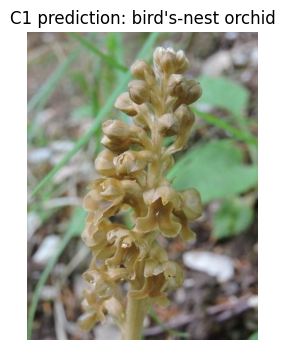

In [4]:
# Eval transform must match the transform used by C1 during testing.
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
])

# Select one high-confidence correct case.
test_row = correct_cases.iloc[0]
image_path = DATA_ROOT / test_row["image_path"]

print("Image path:", image_path)
print("Image exists:", image_path.exists())

image = Image.open(image_path).convert("RGB")
x = eval_transform(image).unsqueeze(0).to(DEVICE)

with torch.inference_mode():
    logits = c1_model(x)
    probabilities = logits.softmax(dim=1)

predicted_class = int(logits.argmax(dim=1).item())
confidence = float(probabilities[0, predicted_class].item())

prediction_check = pd.DataFrame([{
    "true_class": readable_label(int(test_row["true_class"])),
    "saved_prediction": readable_label(int(test_row["predicted_class"])),
    "live_prediction": readable_label(predicted_class),
    "saved_confidence": float(test_row["confidence"]),
    "live_confidence": confidence,
    "prediction_matches": predicted_class == int(test_row["predicted_class"]),
}])

display(prediction_check)

plt.figure(figsize=(5, 4))
plt.imshow(image)
plt.title(f"C1 prediction: {readable_label(predicted_class)}")
plt.axis("off")
plt.show()

## 5. Grad-CAM Implementation

In [6]:
def make_gradcam(model, image_tensor, target_class, target_layer):
    """
    Compute Grad-CAM heatmap for one image and one target class.

    model: trained CNN
    image_tensor: shape [1, 3, H, W]
    target_class: class index to explain
    target_layer: convolutional layer used for Grad-CAM
    """
    model.eval()

    activations = []
    gradients = []

    def forward_hook(module, input, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_full_backward_hook(backward_hook)

    model.zero_grad(set_to_none=True)

    # Important: do NOT use torch.no_grad() here.
    # Grad-CAM needs gradients from the target class score.
    logits = model(image_tensor)
    score = logits[0, target_class]
    score.backward()

    activation = activations[0].detach()      # [1, C, H, W]
    gradient = gradients[0].detach()          # [1, C, H, W]

    # Global-average-pool gradients to get one importance weight per channel.
    weights = gradient.mean(dim=(2, 3), keepdim=True)

    # Weighted sum of activation maps.
    cam = (weights * activation).sum(dim=1).squeeze(0)

    # ReLU keeps only positive evidence for the target class.
    cam = torch.relu(cam)

    # Normalize to 0-1.
    cam = cam - cam.min()
    if cam.max() > 0:
        cam = cam / cam.max()

    heatmap = cam.cpu().numpy()

    forward_handle.remove()
    backward_handle.remove()

    return heatmap, logits.detach()


def overlay_heatmap_on_image(image, heatmap, alpha=0.45, cmap_name="jet"):
    """
    Resize heatmap to original image size and overlay it on the RGB image.
    """
    image_array = np.array(image).astype(np.float32) / 255.0

    heatmap_image = Image.fromarray(np.uint8(heatmap * 255))
    heatmap_image = heatmap_image.resize(image.size, resample=Image.BILINEAR)
    heatmap_resized = np.array(heatmap_image).astype(np.float32) / 255.0

    cmap = plt.get_cmap(cmap_name)
    heatmap_color = cmap(heatmap_resized)[..., :3]

    overlay = (1 - alpha) * image_array + alpha * heatmap_color
    overlay = np.clip(overlay, 0, 1)

    return heatmap_resized, overlay


def show_gradcam_panel(image, heatmap_resized, overlay, title):
    """
    Display original image, heatmap, and overlay side by side.
    """
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(image)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(heatmap_resized, cmap="jet")
    axes[1].set_title("Grad-CAM heatmap")
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title("Overlay")
    axes[2].axis("off")

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## 6. Single-image Grad-CAM Demo

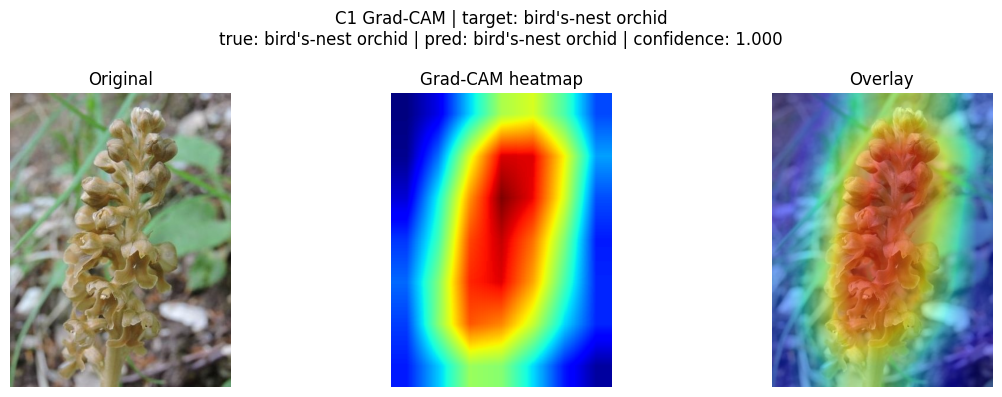

Grad-CAM heatmap shape: (7, 7)
Target layer: model.layer4[-1]
Target class: 293 bird's-nest orchid


In [7]:
# Use the same image from the prediction test.
demo_row = test_row
demo_image_path = DATA_ROOT / demo_row["image_path"]

demo_image = Image.open(demo_image_path).convert("RGB")
demo_tensor = eval_transform(demo_image).unsqueeze(0).to(DEVICE)

# To explain the model's decision, use the predicted class as the Grad-CAM target.
# This follows the handover instruction from C.
demo_target_class = predicted_class

heatmap, demo_logits = make_gradcam(
    model=c1_model,
    image_tensor=demo_tensor,
    target_class=demo_target_class,
    target_layer=target_layer,
)

heatmap_resized, overlay = overlay_heatmap_on_image(demo_image, heatmap)

demo_title = (
    f"C1 Grad-CAM | target: {readable_label(demo_target_class)}\n"
    f"true: {readable_label(int(demo_row['true_class']))} | "
    f"pred: {readable_label(predicted_class)} | "
    f"confidence: {confidence:.3f}"
)

show_gradcam_panel(demo_image, heatmap_resized, overlay, demo_title)

print("Grad-CAM heatmap shape:", heatmap.shape)
print("Target layer:", "model.layer4[-1]")
print("Target class:", demo_target_class, readable_label(demo_target_class))

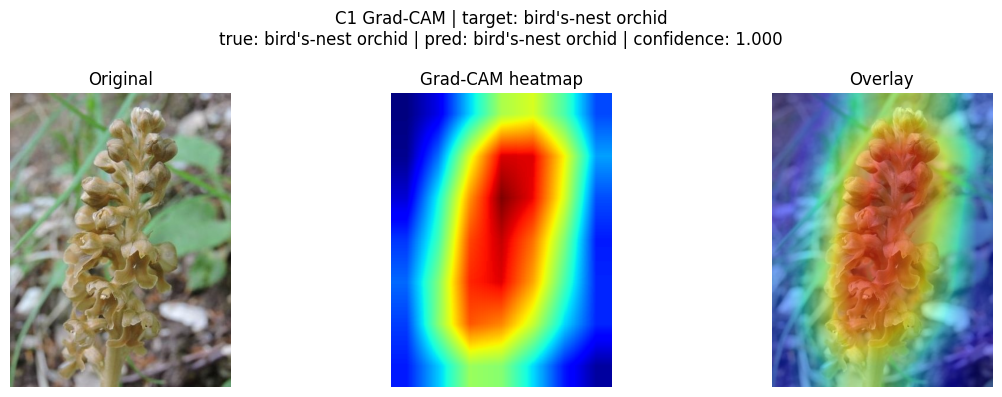

Saved to: C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\demo_correct_birds_nest_orchid_gradcam.png


In [8]:
# Save the first Grad-CAM demo panel.
demo_output_path = OUTPUT_DIR / "demo_correct_birds_nest_orchid_gradcam.png"

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(demo_image)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(heatmap_resized, cmap="jet")
axes[1].set_title("Grad-CAM heatmap")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("Overlay")
axes[2].axis("off")

fig.suptitle(demo_title)
fig.tight_layout()
fig.savefig(demo_output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved to:", demo_output_path)

## 7. Helper Function for Saving Case Panels

In [9]:
def run_gradcam_for_case(row, case_type, output_name=None):
    """
    Generate Grad-CAM panel for one case row and save the figure.

    row: one row from correct_cases / error_cases / predictions
    case_type: text label such as 'correct' or 'error'
    output_name: optional filename
    """
    image_path = DATA_ROOT / row["image_path"]
    image = Image.open(image_path).convert("RGB")
    tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

    # Explain the model's predicted class.
    target_class = int(row["predicted_class"])

    heatmap, logits = make_gradcam(
        model=c1_model,
        image_tensor=tensor,
        target_class=target_class,
        target_layer=target_layer,
    )

    probabilities = logits.softmax(dim=1)
    live_prediction = int(logits.argmax(dim=1).item())
    live_confidence = float(probabilities[0, live_prediction].item())

    heatmap_resized, overlay = overlay_heatmap_on_image(image, heatmap)

    true_label = readable_label(int(row["true_class"]))
    pred_label = readable_label(int(row["predicted_class"]))

    title = (
        f"C1 Grad-CAM | {case_type}\n"
        f"true: {true_label} | pred: {pred_label} | "
        f"confidence: {float(row['confidence']):.3f}"
    )

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(image)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(heatmap_resized, cmap="jet")
    axes[1].set_title("Grad-CAM heatmap")
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title("Overlay")
    axes[2].axis("off")

    fig.suptitle(title)
    fig.tight_layout()

    if output_name is None:
        image_id = row.get("image_id", "unknown")
        output_name = f"{case_type}_{image_id}_gradcam.png"

    output_path = OUTPUT_DIR / output_name
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()

    case_record = {
        "case_type": case_type,
        "image_path": row["image_path"],
        "image_id": row.get("image_id", None),
        "true_class": int(row["true_class"]),
        "true_label": true_label,
        "predicted_class": int(row["predicted_class"]),
        "predicted_label": pred_label,
        "saved_confidence": float(row["confidence"]),
        "live_prediction": live_prediction,
        "live_confidence": live_confidence,
        "target_class": target_class,
        "target_label": pred_label,
        "target_layer": "model.layer4[-1]",
        "output_path": str(output_path),
    }

    return case_record

## 8. Grad-CAM for Correct Cases

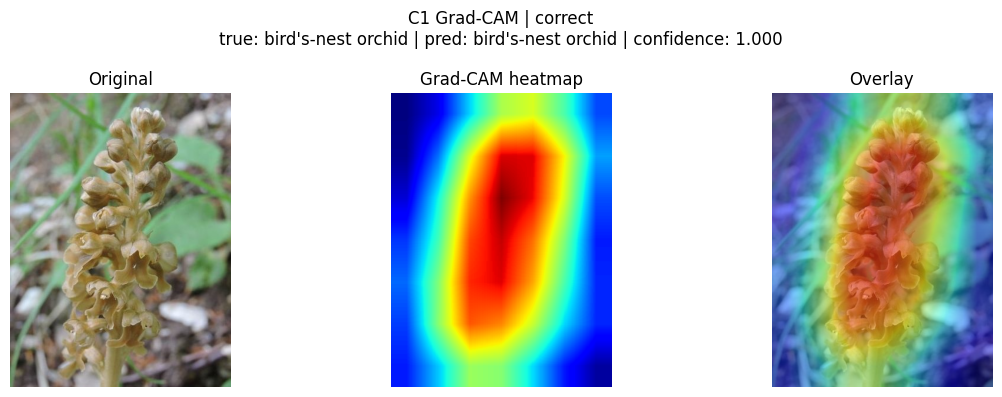

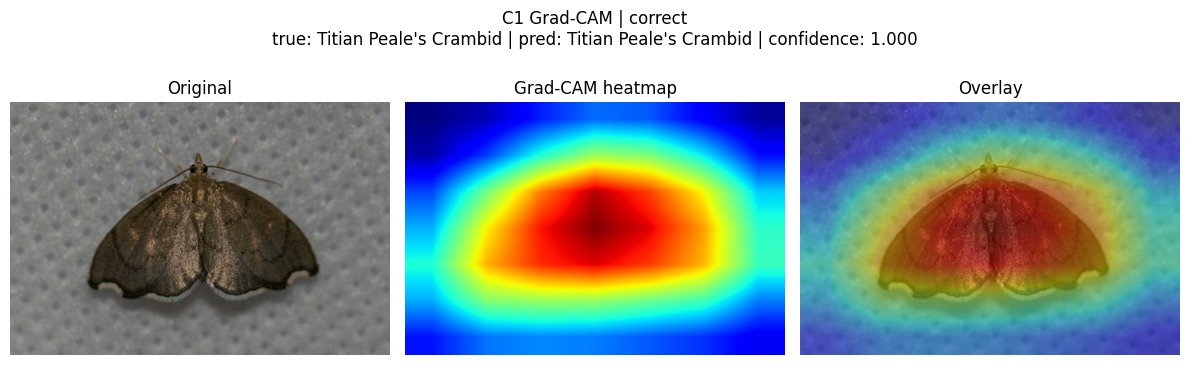

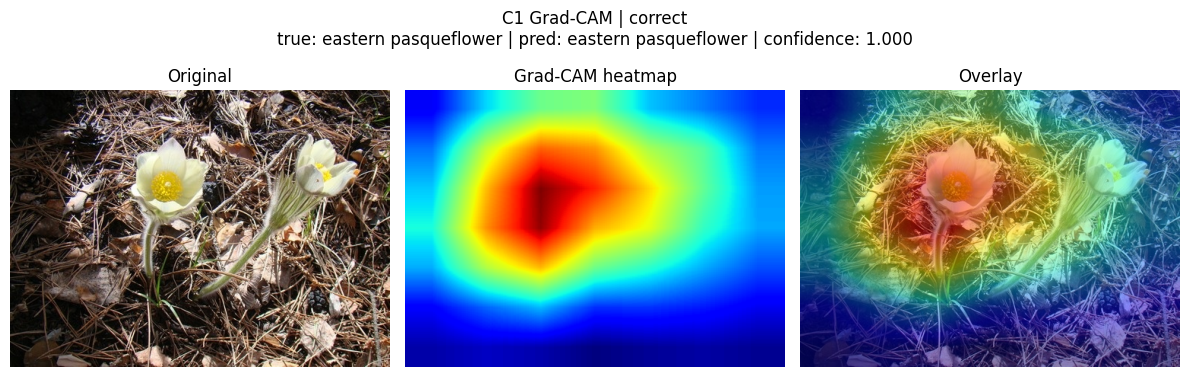

,case_type,image_id,true_label,predicted_label,saved_confidence,target_layer,output_path
0,correct,2775007,bird's-nest orchid,bird's-nest orchid,1.000000,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
1,correct,2702504,Titian Peale's Crambid,Titian Peale's Crambid,1.000000,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
2,correct,2784415,eastern pasqueflower,eastern pasqueflower,0.999998,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...


In [10]:
correct_records = []

# Use the top 3 high-confidence correct cases as reproducible examples.
for i, (_, row) in enumerate(correct_cases.head(3).iterrows(), start=1):
    record = run_gradcam_for_case(
        row=row,
        case_type="correct",
        output_name=f"correct_{i}_{int(row['image_id'])}_gradcam.png",
    )
    correct_records.append(record)

correct_records_df = pd.DataFrame(correct_records)
display(correct_records_df[[
    "case_type",
    "image_id",
    "true_label",
    "predicted_label",
    "saved_confidence",
    "target_layer",
    "output_path",
]])

## 9. Grad-CAM for Error Cases

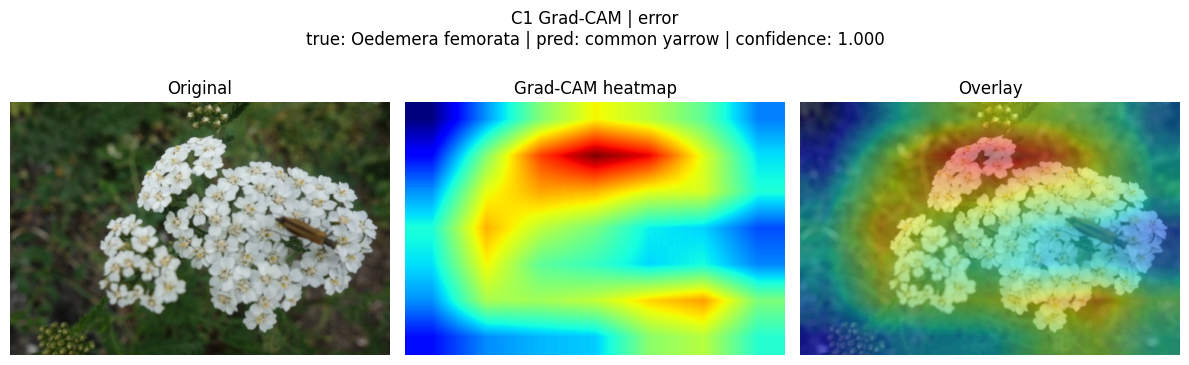

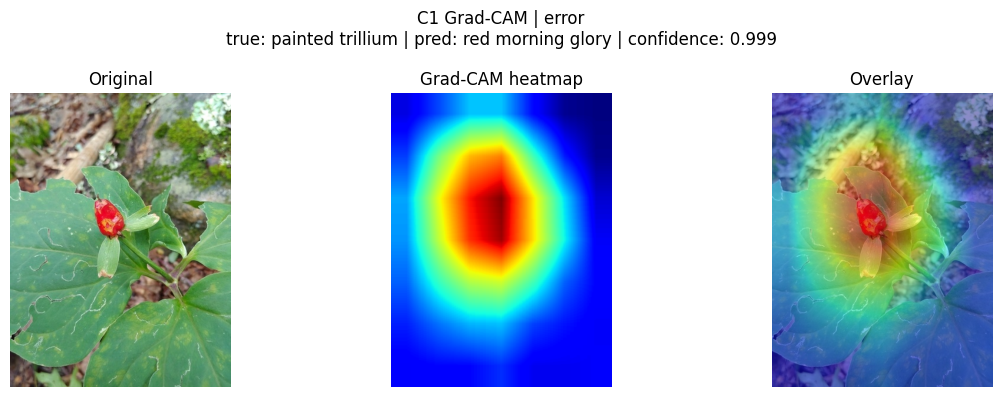

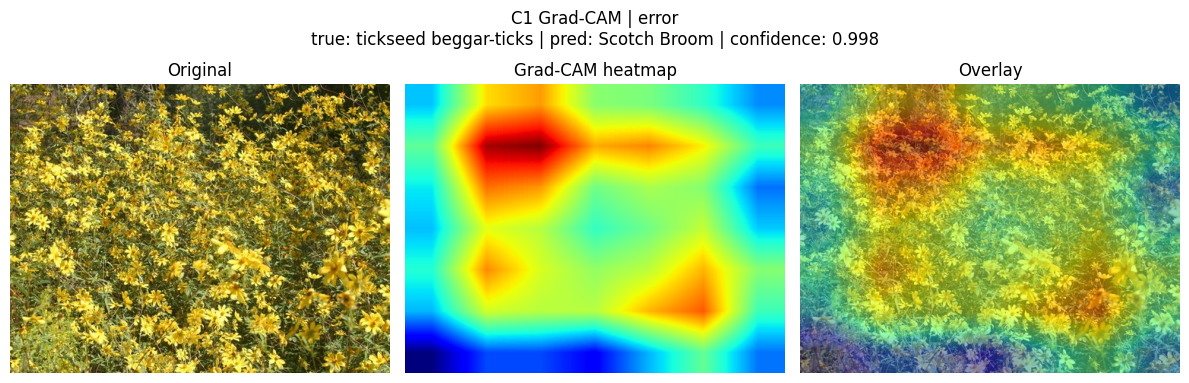

,case_type,image_id,true_label,predicted_label,saved_confidence,target_layer,output_path
0,error,2720812,Oedemera femorata,common yarrow,0.999692,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
1,error,2764281,painted trillium,red morning glory,0.998835,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
2,error,2692154,tickseed beggar-ticks,Scotch Broom,0.997792,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...


In [11]:
error_records = []

# Use the top 3 high-confidence error cases as reproducible examples.
for i, (_, row) in enumerate(error_cases.head(3).iterrows(), start=1):
    record = run_gradcam_for_case(
        row=row,
        case_type="error",
        output_name=f"error_{i}_{int(row['image_id'])}_gradcam.png",
    )
    error_records.append(record)

error_records_df = pd.DataFrame(error_records)
display(error_records_df[[
    "case_type",
    "image_id",
    "true_label",
    "predicted_label",
    "saved_confidence",
    "target_layer",
    "output_path",
]])

## 10. Grad-CAM for Confusion Pair Cases

Top confusion pair:
Class A: 146 Imperial Eagle
Class B: 147 European Honey-buzzard
A -> B errors: 5
B -> A errors: 1
Same genus: False
Same family: True


,image_path,image_id,true_class,predicted_class,confidence,top5_classes
1461,val/03120_Animalia_Chordata_Aves_Accipitriform...,2739832,146,147,0.819524,"[147, 146, 93, 216, 186]"
1473,val/03177_Animalia_Chordata_Aves_Accipitriform...,2749831,147,146,0.749698,"[146, 151, 180, 178, 193]"
1468,val/03120_Animalia_Chordata_Aves_Accipitriform...,2749978,146,147,0.632671,"[147, 146, 199, 172, 180]"
1469,val/03120_Animalia_Chordata_Aves_Accipitriform...,2775215,146,147,0.530683,"[147, 178, 181, 146, 174]"
1462,val/03120_Animalia_Chordata_Aves_Accipitriform...,2746827,146,147,0.528254,"[147, 146, 177, 164, 159]"


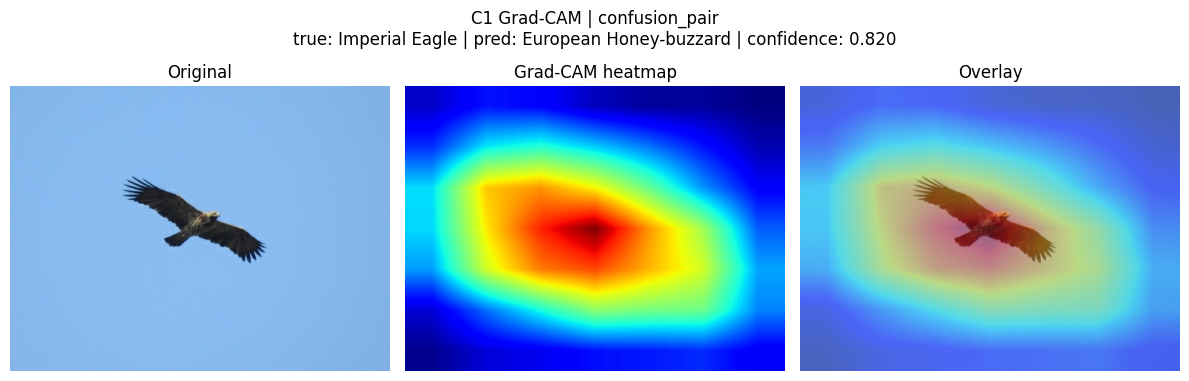

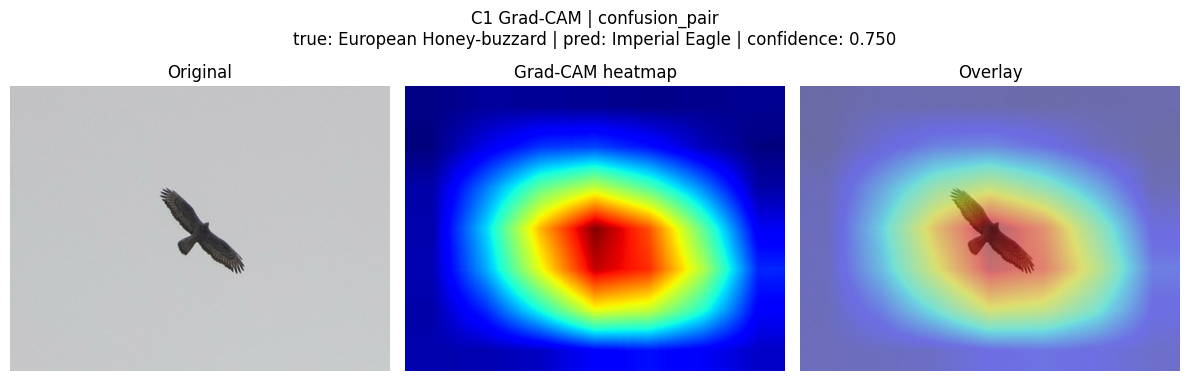

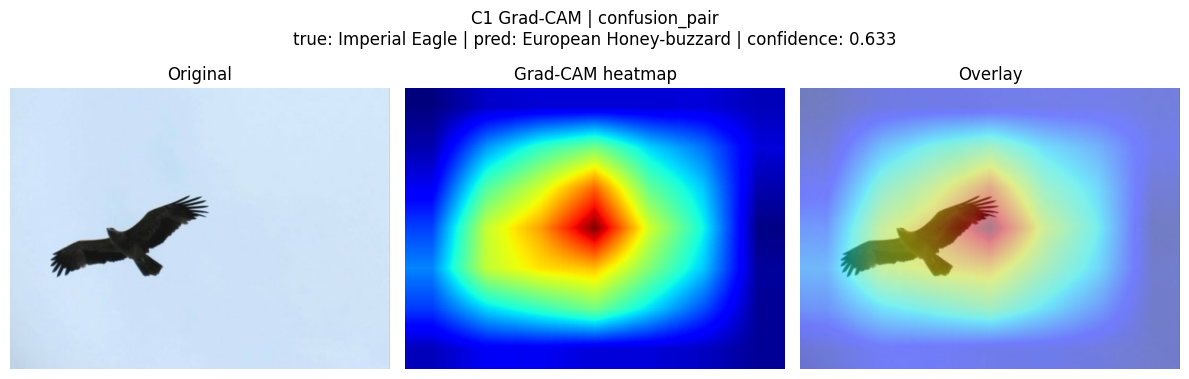

,case_type,image_id,true_label,predicted_label,saved_confidence,target_layer,output_path
0,confusion_pair,2739832,Imperial Eagle,European Honey-buzzard,0.819524,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
1,confusion_pair,2749831,European Honey-buzzard,Imperial Eagle,0.749698,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
2,confusion_pair,2749978,Imperial Eagle,European Honey-buzzard,0.632671,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...


In [12]:
# Select the top confusion pair.
top_pair = confusion_pairs.iloc[0]

class_a = int(top_pair["class_a"])
class_b = int(top_pair["class_b"])

print("Top confusion pair:")
print("Class A:", class_a, readable_label(class_a))
print("Class B:", class_b, readable_label(class_b))
print("A -> B errors:", int(top_pair["a_to_b"]))
print("B -> A errors:", int(top_pair["b_to_a"]))
print("Same genus:", bool(top_pair["same_genus"]))
print("Same family:", bool(top_pair["same_family"]))

# Find examples where class A was predicted as class B, and class B was predicted as class A.
pair_errors = predictions[
    ((predictions["true_class"] == class_a) & (predictions["predicted_class"] == class_b)) |
    ((predictions["true_class"] == class_b) & (predictions["predicted_class"] == class_a))
].copy()

pair_errors = pair_errors.sort_values("confidence", ascending=False)

display(pair_errors[[
    "image_path",
    "image_id",
    "true_class",
    "predicted_class",
    "confidence",
    "top5_classes"
]].head(5))

confusion_records = []

# Generate Grad-CAM for up to 3 examples from this confusion pair.
for i, (_, row) in enumerate(pair_errors.head(3).iterrows(), start=1):
    record = run_gradcam_for_case(
        row=row,
        case_type="confusion_pair",
        output_name=f"confusion_pair_{i}_{int(row['image_id'])}_gradcam.png",
    )
    confusion_records.append(record)

confusion_records_df = pd.DataFrame(confusion_records)
display(confusion_records_df[[
    "case_type",
    "image_id",
    "true_label",
    "predicted_label",
    "saved_confidence",
    "target_layer",
    "output_path",
]])

## 11. Save Case Summary

In [13]:
all_case_records = pd.concat(
    [
        correct_records_df,
        error_records_df,
        confusion_records_df,
    ],
    ignore_index=True,
)

case_summary_path = OUTPUT_DIR / "gradcam_case_summary.csv"
all_case_records.to_csv(case_summary_path, index=False)

display(all_case_records[[
    "case_type",
    "image_id",
    "true_label",
    "predicted_label",
    "saved_confidence",
    "target_label",
    "target_layer",
    "output_path",
]])

print("Saved case summary to:", case_summary_path)

,case_type,image_id,true_label,predicted_label,saved_confidence,target_label,target_layer,output_path
0,correct,2775007,bird's-nest orchid,bird's-nest orchid,1.000000,bird's-nest orchid,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
1,correct,2702504,Titian Peale's Crambid,Titian Peale's Crambid,1.000000,Titian Peale's Crambid,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
2,correct,2784415,eastern pasqueflower,eastern pasqueflower,0.999998,eastern pasqueflower,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
3,error,2720812,Oedemera femorata,common yarrow,0.999692,common yarrow,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
4,error,2764281,painted trillium,red morning glory,0.998835,red morning glory,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
5,error,2692154,tickseed beggar-ticks,Scotch Broom,0.997792,Scotch Broom,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
6,confusion_pair,2739832,Imperial Eagle,European Honey-buzzard,0.819524,European Honey-buzzard,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
7,confusion_pair,2749831,European Honey-buzzard,Imperial Eagle,0.749698,Imperial Eagle,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...
8,confusion_pair,2749978,Imperial Eagle,European Honey-buzzard,0.632671,European Honey-buzzard,model.layer4[-1],C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\...


Saved case summary to: C:\Users\79040\Desktop\ctoe\e_gradcam_outputs\gradcam_case_summary.csv


## 12. Scratch vs Pretrained ResNet-18 Grad-CAM Comparison



This section applies the same Grad-CAM procedure to Member D's pretrained ResNet-18.  
For a fair comparison, the same selected test images from the C1 analysis are reused.  
For each model, the Grad-CAM target class is that model's own predicted class, so the visualisation explains the decision made by that model.


In [ ]:
D_OUTPUT_ROOT = PROJECT_ROOT / "experiment_workspace" / "D_member_outputs"
D_RESNET_DIR = D_OUTPUT_ROOT / "resnet18_pretrained"
D_COMPARISON_DIR = OUTPUT_DIR / "scratch_vs_pretrained_resnet18"
D_COMPARISON_DIR.mkdir(exist_ok=True)

d_checks = {
    "D_OUTPUT_ROOT": D_OUTPUT_ROOT.exists(),
    "D_RESNET_DIR": D_RESNET_DIR.exists(),
    "D checkpoint": (D_RESNET_DIR / "best_checkpoint.pth").exists(),
    "D config.json": (D_RESNET_DIR / "config.json").exists(),
    "D gradcam_info.json": (D_RESNET_DIR / "gradcam_info.json").exists(),
    "D test_predictions.csv": (D_RESNET_DIR / "test_predictions.csv").exists(),
    "D test_metrics.json": (D_RESNET_DIR / "test_metrics.json").exists(),
}

display(pd.DataFrame([
    {"Item": key, "Exists": value} for key, value in d_checks.items()
]))

with open(D_RESNET_DIR / "config.json", "r", encoding="utf-8") as f:
    d_config = json.load(f)
with open(D_RESNET_DIR / "gradcam_info.json", "r", encoding="utf-8") as f:
    d_gradcam_info = json.load(f)
with open(D_RESNET_DIR / "test_metrics.json", "r", encoding="utf-8") as f:
    d_test_metrics = json.load(f)

d_model_info = pd.DataFrame([{
    "model": d_config.get("model_name"),
    "pretrained": d_config.get("pretrained"),
    "weights": d_config.get("weights"),
    "best_epoch": d_config.get("best_epoch"),
    "target_layer": d_gradcam_info.get("target_layer_name"),
    "test_accuracy": d_test_metrics.get("accuracy"),
    "test_macro_f1": d_test_metrics.get("macro_f1"),
    "test_inference_time_seconds": d_test_metrics.get("inference_time_seconds"),
}])

display(d_model_info)


### Load D's Pretrained ResNet-18

D's checkpoint stores the weights under `model_state_dict`.  
The architecture is still ResNet-18 with a 500-class final layer, so it can be loaded almost like C1.  
The target layer is also `model.layer4[-1]`, which makes the comparison with C1 especially direct.


In [ ]:
# Load Member D's pretrained ResNet-18.
d_resnet_model = models.resnet18(weights=None)
d_resnet_model.fc = nn.Linear(d_resnet_model.fc.in_features, NUM_CLASSES)

d_checkpoint = torch.load(D_RESNET_DIR / "best_checkpoint.pth", map_location=DEVICE)
d_resnet_model.load_state_dict(d_checkpoint["model_state_dict"])
d_resnet_model = d_resnet_model.to(DEVICE)
d_resnet_model.eval()

d_resnet_target_layer = d_resnet_model.layer4[-1]

d_resnet_predictions_raw = pd.read_csv(D_RESNET_DIR / "test_predictions.csv")
d_resnet_predictions = d_resnet_predictions_raw.rename(columns={
    "true_label": "true_class",
    "pred_label": "predicted_class",
})

d_prediction_lookup = d_resnet_predictions.set_index("image_path")

loaded_d_info = pd.DataFrame([{
    "architecture": "ResNet-18",
    "initialization": "pretrained, ImageNet weights",
    "num_classes": NUM_CLASSES,
    "checkpoint_epoch": int(d_checkpoint["epoch"]),
    "checkpoint_best_val_macro_f1": float(d_checkpoint["best_val_macro_f1"]),
    "gradcam_target_layer": "model.layer4[-1]",
    "device": str(DEVICE),
    "prediction_rows": len(d_resnet_predictions),
}])

display(loaded_d_info)
display(d_resnet_predictions.head(3))


### Verify One D Prediction

Before producing comparison figures, this cell checks that a live prediction from the loaded D model matches the saved prediction file.  
If this does not match, the most likely causes are preprocessing mismatch, class mapping mismatch, or the wrong checkpoint.


In [ ]:
# Check D live inference on the first selected C1 case.
d_check_case = all_case_records.iloc[0]
d_check_image_path = DATA_ROOT / d_check_case["image_path"]
d_check_saved = d_prediction_lookup.loc[d_check_case["image_path"]]

d_check_image = Image.open(d_check_image_path).convert("RGB")
d_check_tensor = eval_transform(d_check_image).unsqueeze(0).to(DEVICE)

with torch.inference_mode():
    d_check_logits = d_resnet_model(d_check_tensor)
    d_check_probabilities = d_check_logits.softmax(dim=1)

d_live_prediction = int(d_check_logits.argmax(dim=1).item())
d_live_confidence = float(d_check_probabilities[0, d_live_prediction].item())

d_prediction_check = pd.DataFrame([{
    "image_path": d_check_case["image_path"],
    "true_class": readable_label(int(d_check_saved["true_class"])),
    "saved_prediction": readable_label(int(d_check_saved["predicted_class"])),
    "live_prediction": readable_label(d_live_prediction),
    "saved_confidence": float(d_check_saved["confidence"]),
    "live_confidence": d_live_confidence,
    "prediction_matches": d_live_prediction == int(d_check_saved["predicted_class"]),
}])

display(d_prediction_check)


### Generate Same-Image Comparison Panels

Each output figure has five columns: original image, C1 scratch heatmap, C1 scratch overlay, D pretrained heatmap, and D pretrained overlay.  
This is the main visual evidence for discussing whether pretraining changes what the model focuses on.


In [ ]:
def model_gradcam_outputs(model, model_target_layer, image, target_class):
    """
    Compute Grad-CAM outputs for one model on one PIL image.
    The target class should be the class whose decision we want to explain.
    """
    tensor = eval_transform(image).unsqueeze(0).to(DEVICE)
    heatmap, logits = make_gradcam(
        model=model,
        image_tensor=tensor,
        target_class=int(target_class),
        target_layer=model_target_layer,
    )
    probabilities = logits.softmax(dim=1)
    live_prediction = int(logits.argmax(dim=1).item())
    live_confidence = float(probabilities[0, live_prediction].item())
    heatmap_resized, overlay = overlay_heatmap_on_image(image, heatmap)
    return {
        "heatmap": heatmap,
        "heatmap_resized": heatmap_resized,
        "overlay": overlay,
        "live_prediction": live_prediction,
        "live_confidence": live_confidence,
    }


def run_scratch_vs_pretrained_comparison(case_row, output_name=None):
    """
    Compare C1 scratch ResNet-18 and D pretrained ResNet-18 on the same image.
    Each model is explained with its own predicted class as the Grad-CAM target.
    """
    image_path = DATA_ROOT / case_row["image_path"]
    image = Image.open(image_path).convert("RGB")

    c1_target_class = int(case_row["predicted_class"])
    d_saved = d_prediction_lookup.loc[case_row["image_path"]]
    d_target_class = int(d_saved["predicted_class"])

    c1_outputs = model_gradcam_outputs(
        model=c1_model,
        model_target_layer=target_layer,
        image=image,
        target_class=c1_target_class,
    )
    d_outputs = model_gradcam_outputs(
        model=d_resnet_model,
        model_target_layer=d_resnet_target_layer,
        image=image,
        target_class=d_target_class,
    )

    true_label = readable_label(int(case_row["true_class"]))
    c1_pred_label = readable_label(c1_target_class)
    d_pred_label = readable_label(d_target_class)

    fig, axes = plt.subplots(1, 5, figsize=(18, 4))

    axes[0].imshow(image)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(c1_outputs["heatmap_resized"], cmap="jet")
    axes[1].set_title("C1 Scratch heatmap")
    axes[1].axis("off")

    axes[2].imshow(c1_outputs["overlay"])
    axes[2].set_title("C1 Scratch overlay")
    axes[2].axis("off")

    axes[3].imshow(d_outputs["heatmap_resized"], cmap="jet")
    axes[3].set_title("D Pretrained heatmap")
    axes[3].axis("off")

    axes[4].imshow(d_outputs["overlay"])
    axes[4].set_title("D Pretrained overlay")
    axes[4].axis("off")

    title = (
        f"{case_row['case_type']} | true: {true_label}\n"
        f"C1 pred: {c1_pred_label} ({float(case_row['saved_confidence']):.3f}) | "
        f"D pred: {d_pred_label} ({float(d_saved['confidence']):.3f})"
    )
    fig.suptitle(title)
    fig.tight_layout()

    if output_name is None:
        image_id = int(case_row["image_id"]) if pd.notna(case_row.get("image_id")) else "unknown"
        output_name = f"comparison_{case_row['case_type']}_{image_id}_gradcam.png"

    output_path = D_COMPARISON_DIR / output_name
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    return {
        "case_type": case_row["case_type"],
        "image_path": case_row["image_path"],
        "image_id": case_row["image_id"],
        "true_class": int(case_row["true_class"]),
        "true_label": true_label,
        "c1_predicted_class": c1_target_class,
        "c1_predicted_label": c1_pred_label,
        "c1_saved_confidence": float(case_row["saved_confidence"]),
        "c1_live_prediction": c1_outputs["live_prediction"],
        "c1_live_confidence": c1_outputs["live_confidence"],
        "d_predicted_class": d_target_class,
        "d_predicted_label": d_pred_label,
        "d_saved_confidence": float(d_saved["confidence"]),
        "d_live_prediction": d_outputs["live_prediction"],
        "d_live_confidence": d_outputs["live_confidence"],
        "c1_target_layer": "model.layer4[-1]",
        "d_target_layer": "model.layer4[-1]",
        "comparison_output_path": str(output_path),
    }


In [ ]:
comparison_records = []

# Reuse the same final cases selected in the C1 analysis.
for i, (_, row) in enumerate(all_case_records.iterrows(), start=1):
    image_id = int(row["image_id"]) if pd.notna(row.get("image_id")) else i
    record = run_scratch_vs_pretrained_comparison(
        case_row=row,
        output_name=f"comparison_{i}_{row['case_type']}_{image_id}_gradcam.png",
    )
    comparison_records.append(record)

comparison_records_df = pd.DataFrame(comparison_records)
comparison_summary_path = D_COMPARISON_DIR / "scratch_vs_pretrained_resnet18_summary.csv"
comparison_records_df.to_csv(comparison_summary_path, index=False)

display(comparison_records_df[[
    "case_type",
    "image_id",
    "true_label",
    "c1_predicted_label",
    "c1_saved_confidence",
    "d_predicted_label",
    "d_saved_confidence",
    "comparison_output_path",
]])

print("Saved comparison summary to:", comparison_summary_path)


### Report Notes for This Comparison

Use these points when writing the E section:

- C1 is the scratch ResNet-18 selected from Member C's validation experiments.
- D is a pretrained ResNet-18 selected from Member D's validation experiments.
- Both models are evaluated on the same selected test images.
- Both Grad-CAM analyses use the same target layer, `model.layer4[-1]`.
- The target class is each model's own predicted class, because the goal is to explain the model's decision.
- Grad-CAM highlights class-discriminative regions, but it should not be treated as strict causal proof.
- Compare correct, error, and confusion-pair examples separately. Focus on whether the activation covers the organism, discriminative body parts, or background/context.


## 13. Add Best D Model: EfficientNet-B0 Grad-CAM Comparison

D's EfficientNet-B0 pretrained model has the highest test performance among the provided D outputs.  
This section adds EfficientNet-B0 to the same-image Grad-CAM comparison.  
Because EfficientNet-B0 has a different architecture from ResNet-18, its Grad-CAM target layer is `model.features[-1]` rather than `model.layer4[-1]`.

In [ ]:
EFFICIENTNET_DIR = D_OUTPUT_ROOT / "efficientnet_b0_pretrained"
THREE_MODEL_COMPARISON_DIR = OUTPUT_DIR / "scratch_vs_pretrained_resnet18_vs_efficientnet_b0"
THREE_MODEL_COMPARISON_DIR.mkdir(exist_ok=True)

eff_checks = {
    "EfficientNet directory": EFFICIENTNET_DIR.exists(),
    "EfficientNet checkpoint": (EFFICIENTNET_DIR / "best_checkpoint.pth").exists(),
    "EfficientNet config.json": (EFFICIENTNET_DIR / "config.json").exists(),
    "EfficientNet gradcam_info.json": (EFFICIENTNET_DIR / "gradcam_info.json").exists(),
    "EfficientNet test_predictions.csv": (EFFICIENTNET_DIR / "test_predictions.csv").exists(),
    "EfficientNet test_metrics.json": (EFFICIENTNET_DIR / "test_metrics.json").exists(),
}

display(pd.DataFrame([
    {"Item": key, "Exists": value} for key, value in eff_checks.items()
]))

with open(EFFICIENTNET_DIR / "config.json", "r", encoding="utf-8") as f:
    eff_config = json.load(f)
with open(EFFICIENTNET_DIR / "gradcam_info.json", "r", encoding="utf-8") as f:
    eff_gradcam_info = json.load(f)
with open(EFFICIENTNET_DIR / "test_metrics.json", "r", encoding="utf-8") as f:
    eff_test_metrics = json.load(f)

eff_model_info = pd.DataFrame([{
    "model": eff_config.get("model_name"),
    "pretrained": eff_config.get("pretrained"),
    "weights": eff_config.get("weights"),
    "best_epoch": eff_config.get("best_epoch"),
    "target_layer": eff_gradcam_info.get("target_layer_name"),
    "test_accuracy": eff_test_metrics.get("accuracy"),
    "test_macro_f1": eff_test_metrics.get("macro_f1"),
    "test_inference_time_seconds": eff_test_metrics.get("inference_time_seconds"),
}])

display(eff_model_info)


### Load D's EfficientNet-B0

EfficientNet-B0 uses `model.classifier[1]` as its final classifier, so the 1000-class ImageNet head is replaced by a 500-class linear layer before loading D's checkpoint.

In [ ]:
# Load Member D's pretrained EfficientNet-B0.
eff_model = models.efficientnet_b0(weights=None)
eff_model.classifier[1] = nn.Linear(eff_model.classifier[1].in_features, NUM_CLASSES)

eff_checkpoint = torch.load(EFFICIENTNET_DIR / "best_checkpoint.pth", map_location=DEVICE)
eff_model.load_state_dict(eff_checkpoint["model_state_dict"])
eff_model = eff_model.to(DEVICE)
eff_model.eval()

eff_target_layer = eff_model.features[-1]

eff_predictions_raw = pd.read_csv(EFFICIENTNET_DIR / "test_predictions.csv")
eff_predictions = eff_predictions_raw.rename(columns={
    "true_label": "true_class",
    "pred_label": "predicted_class",
})
eff_prediction_lookup = eff_predictions.set_index("image_path")

loaded_eff_info = pd.DataFrame([{
    "architecture": "EfficientNet-B0",
    "initialization": "pretrained, ImageNet weights",
    "num_classes": NUM_CLASSES,
    "checkpoint_epoch": int(eff_checkpoint["epoch"]),
    "checkpoint_best_val_macro_f1": float(eff_checkpoint["best_val_macro_f1"]),
    "gradcam_target_layer": "model.features[-1]",
    "device": str(DEVICE),
    "prediction_rows": len(eff_predictions),
}])

display(loaded_eff_info)
display(eff_predictions.head(3))


### Verify One EfficientNet-B0 Prediction

This checks that the loaded EfficientNet-B0 checkpoint reproduces the saved prediction file on one selected image.

In [ ]:
eff_check_case = all_case_records.iloc[0]
eff_check_image_path = DATA_ROOT / eff_check_case["image_path"]
eff_check_saved = eff_prediction_lookup.loc[eff_check_case["image_path"]]

eff_check_image = Image.open(eff_check_image_path).convert("RGB")
eff_check_tensor = eval_transform(eff_check_image).unsqueeze(0).to(DEVICE)

with torch.inference_mode():
    eff_check_logits = eff_model(eff_check_tensor)
    eff_check_probabilities = eff_check_logits.softmax(dim=1)

eff_live_prediction = int(eff_check_logits.argmax(dim=1).item())
eff_live_confidence = float(eff_check_probabilities[0, eff_live_prediction].item())

eff_prediction_check = pd.DataFrame([{
    "image_path": eff_check_case["image_path"],
    "true_class": readable_label(int(eff_check_saved["true_class"])),
    "saved_prediction": readable_label(int(eff_check_saved["predicted_class"])),
    "live_prediction": readable_label(eff_live_prediction),
    "saved_confidence": float(eff_check_saved["confidence"]),
    "live_confidence": eff_live_confidence,
    "prediction_matches": eff_live_prediction == int(eff_check_saved["predicted_class"]),
}])

display(eff_prediction_check)


### Three-Model Grad-CAM Comparison

The figures below compare the same images across three models:

1. C1 Scratch ResNet-18;
2. D Pretrained ResNet-18;
3. D Pretrained EfficientNet-B0.

For readability, each figure shows the original image plus one overlay per model. The summary CSV records each model's prediction, confidence, target class, and target layer.

In [ ]:
def run_three_model_comparison(case_row, output_name=None):
    """
    Compare C1 Scratch ResNet-18, D Pretrained ResNet-18, and D Pretrained EfficientNet-B0.
    Each model is explained using its own predicted class as the Grad-CAM target.
    """
    image_path = DATA_ROOT / case_row["image_path"]
    image = Image.open(image_path).convert("RGB")

    c1_target_class = int(case_row["predicted_class"])
    d_resnet_saved = d_prediction_lookup.loc[case_row["image_path"]]
    d_resnet_target_class = int(d_resnet_saved["predicted_class"])
    eff_saved = eff_prediction_lookup.loc[case_row["image_path"]]
    eff_target_class = int(eff_saved["predicted_class"])

    c1_outputs = model_gradcam_outputs(
        model=c1_model,
        model_target_layer=target_layer,
        image=image,
        target_class=c1_target_class,
    )
    d_resnet_outputs = model_gradcam_outputs(
        model=d_resnet_model,
        model_target_layer=d_resnet_target_layer,
        image=image,
        target_class=d_resnet_target_class,
    )
    eff_outputs = model_gradcam_outputs(
        model=eff_model,
        model_target_layer=eff_target_layer,
        image=image,
        target_class=eff_target_class,
    )

    true_label = readable_label(int(case_row["true_class"]))
    c1_pred_label = readable_label(c1_target_class)
    d_resnet_pred_label = readable_label(d_resnet_target_class)
    eff_pred_label = readable_label(eff_target_class)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].imshow(image)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(c1_outputs["overlay"])
    axes[1].set_title(f"C1 Scratch\n{c1_pred_label}")
    axes[1].axis("off")

    axes[2].imshow(d_resnet_outputs["overlay"])
    axes[2].set_title(f"D ResNet-18\n{d_resnet_pred_label}")
    axes[2].axis("off")

    axes[3].imshow(eff_outputs["overlay"])
    axes[3].set_title(f"D EfficientNet-B0\n{eff_pred_label}")
    axes[3].axis("off")

    title = (
        f"{case_row['case_type']} | true: {true_label}\n"
        f"C1: {float(case_row['saved_confidence']):.3f} | "
        f"D ResNet: {float(d_resnet_saved['confidence']):.3f} | "
        f"EffNet: {float(eff_saved['confidence']):.3f}"
    )
    fig.suptitle(title)
    fig.tight_layout()

    if output_name is None:
        image_id = int(case_row["image_id"]) if pd.notna(case_row.get("image_id")) else "unknown"
        output_name = f"three_model_{case_row['case_type']}_{image_id}_gradcam.png"

    output_path = THREE_MODEL_COMPARISON_DIR / output_name
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    return {
        "case_type": case_row["case_type"],
        "image_path": case_row["image_path"],
        "image_id": case_row["image_id"],
        "true_class": int(case_row["true_class"]),
        "true_label": true_label,
        "c1_predicted_class": c1_target_class,
        "c1_predicted_label": c1_pred_label,
        "c1_saved_confidence": float(case_row["saved_confidence"]),
        "d_resnet_predicted_class": d_resnet_target_class,
        "d_resnet_predicted_label": d_resnet_pred_label,
        "d_resnet_saved_confidence": float(d_resnet_saved["confidence"]),
        "effnet_predicted_class": eff_target_class,
        "effnet_predicted_label": eff_pred_label,
        "effnet_saved_confidence": float(eff_saved["confidence"]),
        "c1_target_layer": "model.layer4[-1]",
        "d_resnet_target_layer": "model.layer4[-1]",
        "effnet_target_layer": "model.features[-1]",
        "comparison_output_path": str(output_path),
    }


In [ ]:
three_model_records = []

for i, (_, row) in enumerate(all_case_records.iterrows(), start=1):
    image_id = int(row["image_id"]) if pd.notna(row.get("image_id")) else i
    record = run_three_model_comparison(
        case_row=row,
        output_name=f"three_model_{i}_{row['case_type']}_{image_id}_gradcam.png",
    )
    three_model_records.append(record)

three_model_records_df = pd.DataFrame(three_model_records)
three_model_summary_path = THREE_MODEL_COMPARISON_DIR / "three_model_gradcam_summary.csv"
three_model_records_df.to_csv(three_model_summary_path, index=False)

display(three_model_records_df[[
    "case_type",
    "image_id",
    "true_label",
    "c1_predicted_label",
    "d_resnet_predicted_label",
    "effnet_predicted_label",
    "effnet_saved_confidence",
    "comparison_output_path",
]])

print("Saved three-model summary to:", three_model_summary_path)


### Report Notes for EfficientNet-B0

EfficientNet-B0 is included because it is D's best-performing pretrained model.  
When reporting these results, mention that the EfficientNet-B0 Grad-CAM target layer is `model.features[-1]`, while both ResNet-18 models use `model.layer4[-1]`.  
Because the architectures differ, the heatmaps are useful for qualitative comparison but are not perfectly layer-equivalent.